# Chapitre 8 - Exercices 8.9 à 8.12

Ce notebook traite les exercices sur les transactions distribuées (cours 5) :

- **8.9** : le coût de 2PC (latence, `fsync`, verrous) et la fréquence des
  transactions en doute ;
- **8.10** : injection exhaustive de pannes du coordinateur et d'un participant ;
  comparaison avec la validation naïve en une phase ;
- **8.11** : un protocole de terminaison coopératif ; quels blocages lève-t-il ?
- **8.12** : « exactement une fois » par déduplication, et l'ordre des étapes
  (section *Exactly-Once Message Processing Revisited*).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sqlite3

from ddia import transactions as tr
from ddia import exactly_once as eo
from ddia.transactions import run_2pc, Participant2PC, Coordinator2PC
from ddia.sim import Network
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## Exercice 8.9 : le coût de 2PC

**Énoncé.** Une transaction touche deux shards. Un aller-retour réseau coûte 0,5 ms
(0,25 ms dans chaque sens) et un `fsync` 2 ms ; on néglige le calcul.

1. Quelle est la latence de validation vue par l'application (de la demande de validation
   à la décision journalisée) avec 2PC ? Comparer à une validation sur un seul nœud.
   Combien de `fsync` et de messages sur le chemin critique ?
2. Combien de temps les verrous sont-ils tenus entre la demande de validation et leur
   libération sur un participant ?
3. Le coordinateur tombe en moyenne une fois par mois ; le système valide 1 000
   transactions distribuées par seconde ; une transaction est « en doute » pendant environ
   2,5 ms. Combien de transactions en doute par an ? Si chaque redémarrage du coordinateur
   prend 5 minutes, combien de « transactions-minutes » de verrous bloqués ?
4. Vérifier les questions 1 et 2 avec `run_2pc`.

**Rappels.** Déroulé de 2PC, promesses, en doute (cours 5, sections 2 à 4 et 7 ; sections
*Two-Phase Commit* et *Holding locks while in doubt*).

**Solution.**

*1.* Le coordinateur envoie `prepare` (0,25 ms), chaque participant écrit ses données et
son vote (`fsync`, 2 ms) et répond (0,25 ms) ; le coordinateur écrit sa décision
(`fsync`, 2 ms). Latence : $0{,}25 + 2 + 0{,}25 + 2 = 4{,}5$ ms, contre 2 ms pour une
validation locale (un `fsync`). Sur le chemin critique : 2 `fsync` séquentiels (ceux des
participants sont en parallèle ; 3 au total) et $2n = 4$ messages ; puis $2n = 4$ messages
hors chemin critique (décision, accusés). La validation distribuée coûte ici 2,25 fois
plus cher.

*2.* Les verrous sont libérés à la réception de la décision, 0,25 ms après son écriture :
4,75 ms après la demande de validation (contre 2 ms en local). Toute transaction
concurrente sur les mêmes lignes attend d'autant plus.

*3.* En moyenne, $1\,000 \times 0{,}0025 = 2{,}5$ transactions sont en doute à un instant
donné. Avec 12 pannes par an : environ **30 transactions en doute par an**, chacune
bloquant ses lignes 5 minutes, soit environ **150 transactions-minutes** de verrous
tenus. Peu en volume, mais chaque incident peut bloquer une partie de l'application
(toutes les transactions qui veulent ces lignes), et un journal perdu les bloque pour
toujours.

latence de validation 2PC : 4.50 ms (local : 2 ms)
verrous tenus après la demande de validation : 4.75 ms


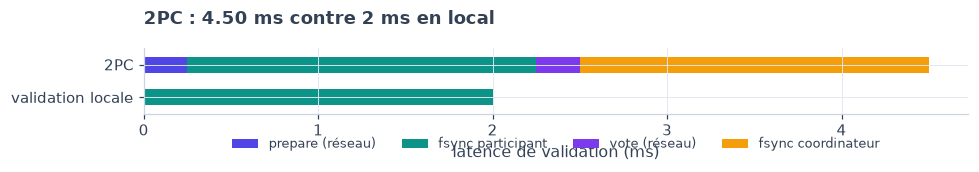

transactions en doute par an : 30 ; transactions-minutes bloquées : 150


In [2]:
run9 = run_2pc(latency=(0.25, 0.25), t_max=20, start_at=0.0, work_time=1.0,
               log_time=2.0, participant_kw=dict(prepare_time=2.0))
demande = 1.0
latence = run9.coord.decided_at - demande
verrous = (run9.summary["verrous_jusqu_à"] - demande).max()
print(f"latence de validation 2PC : {latence:.2f} ms (local : 2 ms)")
print(f"verrous tenus après la demande de validation : {verrous:.2f} ms")
comp = pd.DataFrame({"validation locale": [0, 2, 0, 0], "2PC": [0.25, 2, 0.25, 2]},
                    index=["prepare (réseau)", "fsync participant", "vote (réseau)", "fsync coordinateur"])
ax = comp.T.plot.barh(stacked=True, figsize=(9, 2.8), color=[INDIGO, TEAL, VIOLET, AMBER])
ax.set_xlabel("latence de validation (ms)")
ax.set_title(f"2PC : {comp['2PC'].sum():.2f} ms contre {comp['validation locale'].sum():.0f} ms en local")
ax.legend(fontsize=8.5, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.75))
plt.tight_layout(); plt.show()
print(f"transactions en doute par an : {12 * 1000 * 0.0025:.0f} ; transactions-minutes bloquées : {12 * 1000 * 0.0025 * 5:.0f}")

La simulation retrouve 4,5 ms de latence et 4,75 ms de détention des verrous.

> **À retenir.** 2PC double au moins la latence de validation (deux `fsync` séquentiels et
> un aller-retour de plus) et allonge d'autant la détention des verrous ; les pannes du
> coordinateur, même rares, laissent régulièrement des transactions en doute.

## Exercice 8.10 : injection exhaustive de pannes

**Énoncé.**

1. Faire tomber le coordinateur à l'instant $t_c$ **et** le participant `db1` à
   l'instant $t_p$, pour toutes les paires sur une grille de 0,2 à 7,8 (pas de 0,4),
   chacun redémarrant 6 unités plus tard. Vérifier que la transaction est toujours
   atomique et toujours terminée à la fin de la simulation. Représenter la durée maximale
   de détention des verrous.
2. Même expérience avec la validation naïve en une phase et une panne du seul
   participant : quelle fraction des instants de panne viole l'atomicité ?

**Rappels.** Abandon unilatéral avant le vote, participant en doute après, abandon
présumé au redémarrage du coordinateur (cours 5, sections 3 et 4).

**Solution.** On s'attend à 100 % d'exécutions atomiques et terminées avec 2PC : le
participant qui tombe avant de voter annule à son redémarrage (et vote non si on le lui
demande), celui qui tombe après avoir voté relit son vote et interroge le coordinateur ;
le coordinateur relit sa décision ou présume l'abandon. Avec la validation en une phase,
un participant qui tombe avant de recevoir `commit` annule à son redémarrage pendant que
l'autre valide : l'atomicité est perdue chaque fois que la panne survient entre le début
du travail et la réception de `commit`.

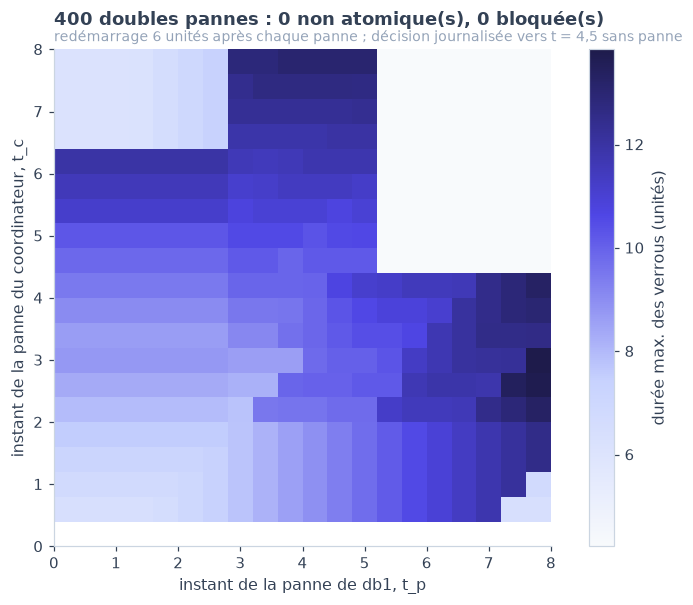

In [3]:
grille = np.round(np.arange(0.2, 8.0, 0.4), 2)
M = np.zeros((len(grille), len(grille)))
non_atomique, non_termine = 0, 0
for i, tc in enumerate(grille):
    for j, tp in enumerate(grille):
        r = run_2pc(crash={"coord": (tc, tc + 6), "db1": (tp, tp + 6)}, t_max=60)
        non_atomique += not r.atomic
        non_termine += "en doute" in set(r.summary["issue"])
        M[i, j] = r.summary["durée_verrous"].max()
fig, ax = plt.subplots(figsize=(7.5, 5.6))
im = ax.imshow(M, origin="lower", cmap="ddia_seq", extent=[grille[0] - 0.2, grille[-1] + 0.2, grille[0] - 0.2, grille[-1] + 0.2])
plt.colorbar(im, ax=ax, label="durée max. des verrous (unités)")
ax.grid(False)
ax.set_xlabel("instant de la panne de db1, t_p")
ax.set_ylabel("instant de la panne du coordinateur, t_c")
ax.set_title(f"{len(grille) ** 2} doubles pannes : {non_atomique} non atomique(s), {non_termine} bloquée(s)")
subtitle(ax, "redémarrage 6 unités après chaque panne ; décision journalisée vers t = 4,5 sans panne")
plt.tight_layout(); plt.show()

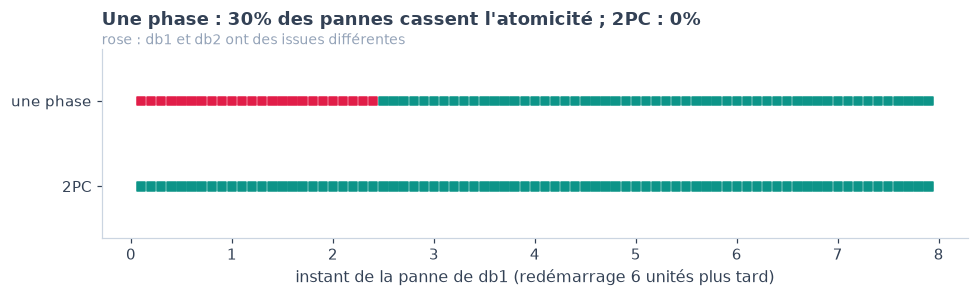

In [4]:
instants = np.round(np.arange(0.1, 8.0, 0.1), 2)
viol_1pc = [not run_2pc(protocol="1pc", crash={"db1": (t, t + 6)}, t_max=40).atomic for t in instants]
viol_2pc = [not run_2pc(crash={"db1": (t, t + 6)}, t_max=40).atomic for t in instants]
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.scatter(instants, np.ones_like(instants), c=[ROSE if v else TEAL for v in viol_1pc], s=30, marker="s")
ax.scatter(instants, np.zeros_like(instants), c=[ROSE if v else TEAL for v in viol_2pc], s=30, marker="s")
ax.set_yticks([0, 1]); ax.set_yticklabels(["2PC", "une phase"])
ax.set_ylim(-0.6, 1.6)
ax.grid(False)
ax.set_xlabel("instant de la panne de db1 (redémarrage 6 unités plus tard)")
ax.set_title(f"Une phase : {np.mean(viol_1pc):.0%} des pannes cassent l'atomicité ; 2PC : {np.mean(viol_2pc):.0%}")
subtitle(ax, "rose : db1 et db2 ont des issues différentes")
plt.tight_layout(); plt.show()

Avec 2PC, les 400 doubles pannes donnent toutes une transaction atomique et terminée ; la
carte montre le prix : quand le coordinateur tombe pendant la phase de préparation, ou
quand db1 tombe après avoir voté, les verrous restent tenus jusqu'aux redémarrages (zones
sombres). Avec la validation en une phase, toute panne de db1 entre la réception de
`begin` et celle de `commit` casse l'atomicité.

> **À retenir.** L'injection exhaustive de pannes est le bon réflexe pour tester un
> protocole : 2PC passe toutes les combinaisons (au prix de verrous tenus longtemps), la
> validation naïve échoue dès qu'un participant tombe au mauvais moment.